# NO2 Pulse Detection 

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from datetime import datetime, timezone
from tqdm import tqdm
from datetime import timedelta

In [2]:
all_no2_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_hourscaled_tempo.parquet'

no2_df = pd.read_parquet(all_no2_file, engine = 'pyarrow')

In [3]:
no2_df =no2_df[no2_df['no2_mean'] >=0].copy()
no2_df = no2_df.drop(columns={'tz_name','hour_scale_factor'})
no2_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,datetime_utc,datetime_local,local_hour,state_name,no2_scaled_by_hour
0,2024-03-01 16:00:00,37.05,-101.45,5.878859e+14,3.473272e+14,20,7.766471e+13,0.090951,0.006863,0.270200,0.017097,0.0,0.0,0.590807,2024-03-01 16:00:00,2024-03-01 10:00:00,10,Kansas,5.095935e+14
1,2024-03-01 16:00:00,37.05,-101.25,9.970334e+14,5.362062e+14,20,1.198994e+14,0.093782,0.003665,0.279736,0.008942,0.0,0.0,0.537802,2024-03-01 16:00:00,2024-03-01 10:00:00,10,Kansas,8.642522e+14
2,2024-03-01 16:00:00,37.05,-101.15,8.684310e+14,5.908427e+14,18,1.392630e+14,0.090637,0.006393,0.270927,0.016931,0.0,0.0,0.680357,2024-03-01 16:00:00,2024-03-01 10:00:00,10,Kansas,7.527766e+14
3,2024-03-01 16:00:00,37.15,-100.65,1.537698e+15,2.809261e+14,20,6.281699e+13,0.086677,0.005071,0.263901,0.012496,0.0,0.0,0.182693,2024-03-01 16:00:00,2024-03-01 10:00:00,10,Kansas,1.332913e+15
4,2024-03-01 16:00:00,37.15,-94.75,1.129261e+15,1.707849e+14,22,3.641146e+13,0.094166,0.003154,0.299863,0.007492,0.0,0.0,0.151236,2024-03-01 16:00:00,2024-03-01 10:00:00,10,Kansas,9.788699e+14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2589511,2024-07-31 23:00:00,43.75,-97.95,1.226792e+15,7.884975e+14,13,2.186899e+14,0.033057,0.025854,0.109373,0.074656,0.0,0.0,0.642731,2024-07-31 23:00:00,2024-07-31 18:00:00,18,South Dakota,8.903654e+14
2589512,2024-07-31 23:00:00,43.75,-97.85,1.067047e+15,7.917712e+14,24,1.616196e+14,0.020792,0.009943,0.078556,0.035800,0.0,0.0,0.742021,2024-07-31 23:00:00,2024-07-31 18:00:00,18,South Dakota,7.744275e+14
2589513,2024-07-31 23:00:00,43.85,-97.85,1.196948e+15,3.982585e+14,17,9.659187e+13,0.059991,0.025293,0.197631,0.069684,0.0,0.0,0.332728,2024-07-31 23:00:00,2024-07-31 18:00:00,18,South Dakota,8.687052e+14
2589514,2024-07-31 23:00:00,44.85,-98.55,9.127368e+14,6.625882e+14,18,1.561735e+14,0.065685,0.015345,0.219664,0.043226,0.0,0.0,0.725936,2024-07-31 23:00:00,2024-07-31 18:00:00,18,South Dakota,6.624342e+14


In [4]:
no2_19 = no2_df[no2_df['local_hour']==19]
no2_19

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,datetime_utc,datetime_local,local_hour,state_name,no2_scaled_by_hour
1206402,2024-05-26 00:00:00,47.75,-103.55,1.647057e+15,9.561154e+14,18,2.253586e+14,0.089439,0.004830,0.266803,0.011741,0.0,0.0,0.580499,2024-05-26 00:00:00,2024-05-25 19:00:00,19,North Dakota,NaN
1255511,2024-05-29 00:00:00,47.55,-102.05,2.154783e+15,1.398586e+15,20,3.127333e+14,0.068534,0.018505,0.192305,0.056079,0.0,0.0,0.649061,2024-05-29 00:00:00,2024-05-28 19:00:00,19,North Dakota,NaN
1255512,2024-05-29 00:00:00,47.75,-102.25,6.164687e+14,3.644042e+14,20,8.148326e+13,0.061945,0.009444,0.168185,0.025133,0.0,0.0,0.591116,2024-05-29 00:00:00,2024-05-28 19:00:00,19,North Dakota,NaN
1255513,2024-05-29 00:00:00,47.95,-102.55,8.597574e+14,2.573220e+14,13,7.136827e+13,0.084360,0.007809,0.223604,0.023067,0.0,0.0,0.299296,2024-05-29 00:00:00,2024-05-28 19:00:00,19,North Dakota,NaN
1321368,2024-05-30 23:00:00,40.65,-87.45,2.559833e+15,1.082860e+15,14,2.894066e+14,0.092585,0.002481,0.286654,0.006862,0.0,0.0,0.423020,2024-05-30 23:00:00,2024-05-30 19:00:00,19,Indiana,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2236859,2024-07-06 23:00:00,40.65,-87.05,1.236621e+15,5.706523e+14,25,1.141305e+14,0.094434,0.001048,0.299674,0.002784,0.0,0.0,0.461461,2024-07-06 23:00:00,2024-07-06 19:00:00,19,Indiana,NaN
2236860,2024-07-06 23:00:00,40.65,-86.85,1.001190e+15,3.440181e+14,16,8.600453e+13,0.092391,0.001866,0.293518,0.004807,0.0,0.0,0.343609,2024-07-06 23:00:00,2024-07-06 19:00:00,19,Indiana,NaN
2236861,2024-07-06 23:00:00,40.65,-86.75,1.461479e+15,6.372849e+14,24,1.300852e+14,0.092904,0.002378,0.293658,0.005234,0.0,0.0,0.436055,2024-07-06 23:00:00,2024-07-06 19:00:00,19,Indiana,NaN
2253773,2024-07-07 23:00:00,40.15,-87.05,1.601482e+15,6.527134e+14,16,1.631784e+14,0.094860,0.002790,0.300230,0.006915,0.0,0.0,0.407568,2024-07-07 23:00:00,2024-07-07 19:00:00,19,Indiana,NaN


In [5]:
hourly = no2_df.groupby('local_hour').agg({'no2_mean': 'mean','no2_scaled_by_hour': 'mean',}).reindex(range(24))

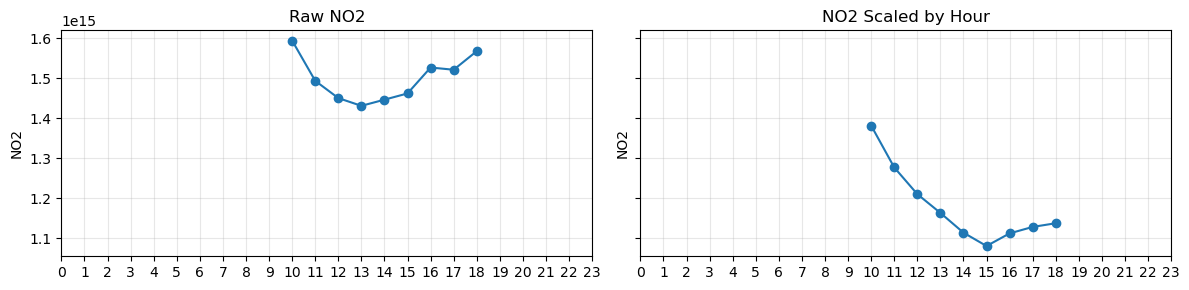

In [6]:
fig, axes = plt.subplots(1,2, figsize=(12, 3), sharex=True, sharey=True)
hourly_day = hourly.loc[7:18]
#raw no2
axes[0].plot(hourly_day.index, hourly_day['no2_mean'], marker='o')
axes[0].set_title('Raw NO2')
axes[0].set_ylabel('NO2')
axes[0].grid(alpha=0.3)

#scaled by hour
axes[1].plot(hourly_day.index, hourly_day['no2_scaled_by_hour'], marker='o')
axes[1].set_title('NO2 Scaled by Hour')
axes[1].set_ylabel('NO2')
axes[1].grid(alpha=0.3)

# #scaled by state and hour
# axes[2].plot(hourly_day.index, hourly_day['no2_scaled_by_state_hour'], marker='o')
# axes[2].set_title('NO2 Scaled by State + Hour')
# axes[2].set_ylabel('NO2')
# axes[2].set_xlabel('Local Hour of Day')
# axes[2].grid(alpha=0.3)

plt.xticks(range(24))
plt.tight_layout()
plt.show()

# How many days until a grid cell reaches 50 observations?

In [7]:
def days_to_40_obs(sub_df):
    sub_df = sub_df.copy()
    if len(sub_df) <40:
        return pd.Series({'days_to_40_obs': pd.NA})
    #want date of 1st and the 40th observation 
    start_date =sub_df['datetime_local'].iloc[0]
    end_date =sub_df['datetime_local'].iloc[39]
    
    #counting days between 1st adn 40th 
    total_days =(end_date - start_date).days + 1
    return pd.Series({'days_to_40_obs':total_days})

obs_to_40_count = (no2_df.groupby(['grid_lat', 'grid_lon'], group_keys=False).apply(days_to_40_obs).reset_index())

In [8]:
obs_to_40_count

,grid_lat,grid_lon,days_to_40_obs
0,36.05,-91.15,13
1,36.05,-91.05,18
2,36.05,-90.95,18
3,36.05,-90.85,11
4,36.05,-90.75,11
...,...,...,...
8964,48.95,-97.25,43
8965,48.95,-97.15,44
8966,48.95,-97.05,44
8967,48.95,-96.95,48


In [9]:
obs_to_40_count['days_to_40_obs']=pd.to_numeric(obs_to_40_count['days_to_40_obs'])
obs_to_40_count.describe()

,grid_lat,grid_lon,days_to_40_obs
count,8969.000000,8969.000000,8969.000000
mean,42.848149,-94.348718,34.983387
std,3.253904,4.845110,15.337595
min,36.050000,-103.950000,10.000000
25%,40.350000,-97.950000,20.000000
50%,42.350000,-95.550000,35.000000
75%,45.450000,-90.350000,43.000000
max,48.950000,-81.750000,93.000000


In [10]:
Q1=20
Q3=43
IQR=Q3-Q1
max = Q3 + (1.5*IQR)
print(f'the max (before outliers) is: {max}')

count_outliers = (obs_to_40_count['days_to_40_obs'] > max).sum()
count_outliers

the max (before outliers) is: 77.5


67

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


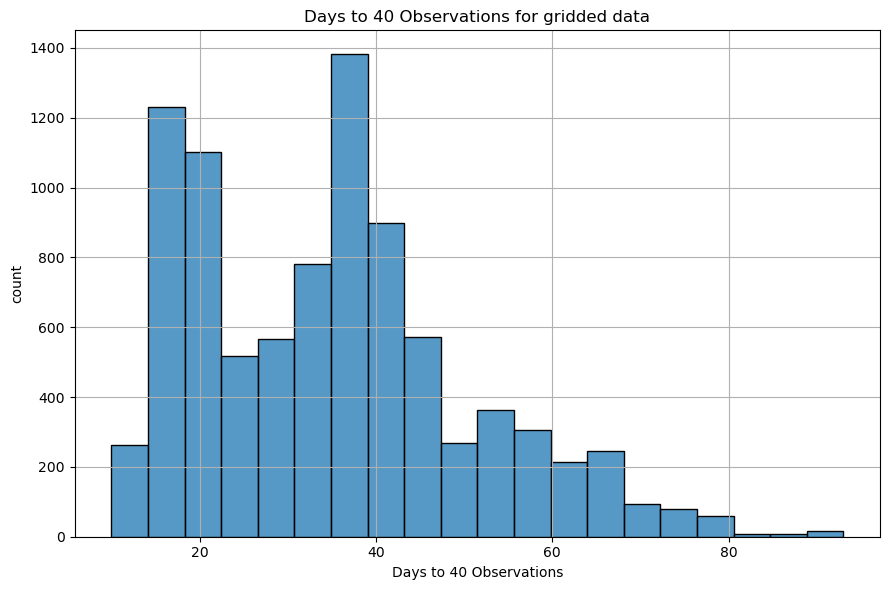

In [11]:
plt.figure(figsize=(9,6))
sns.histplot(x='days_to_40_obs', bins=20,data=obs_to_40_count)

plt.title('Days to 40 Observations for gridded data')
plt.ylabel('count')
plt.xlabel('Days to 40 Observations')
plt.tight_layout()
plt.grid(True)
plt.show()

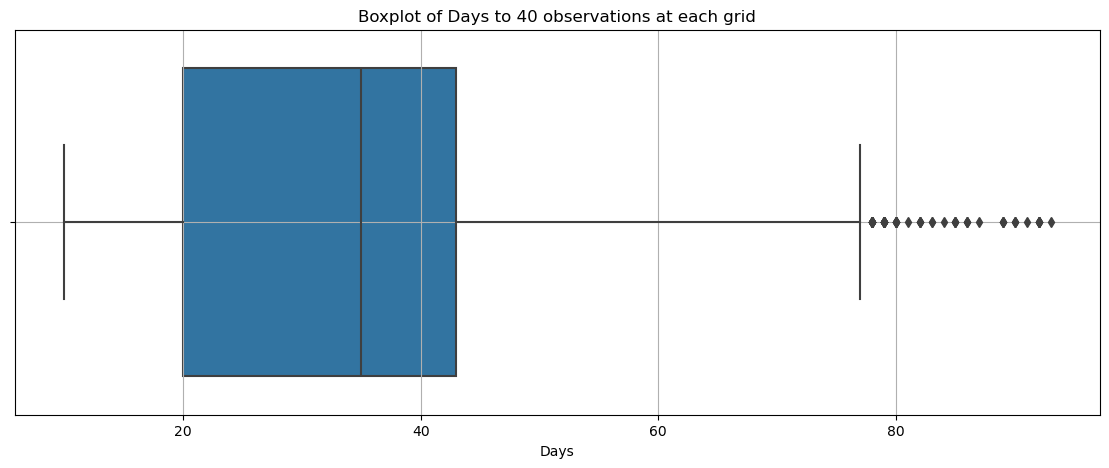

In [12]:
#boxplot 
plt.figure(figsize=(14,5))
sns.boxplot(x=obs_to_40_count['days_to_40_obs'])
plt.title('Boxplot of Days to 40 observations at each grid')
plt.xlabel('Days')
plt.grid(True)
plt.show()

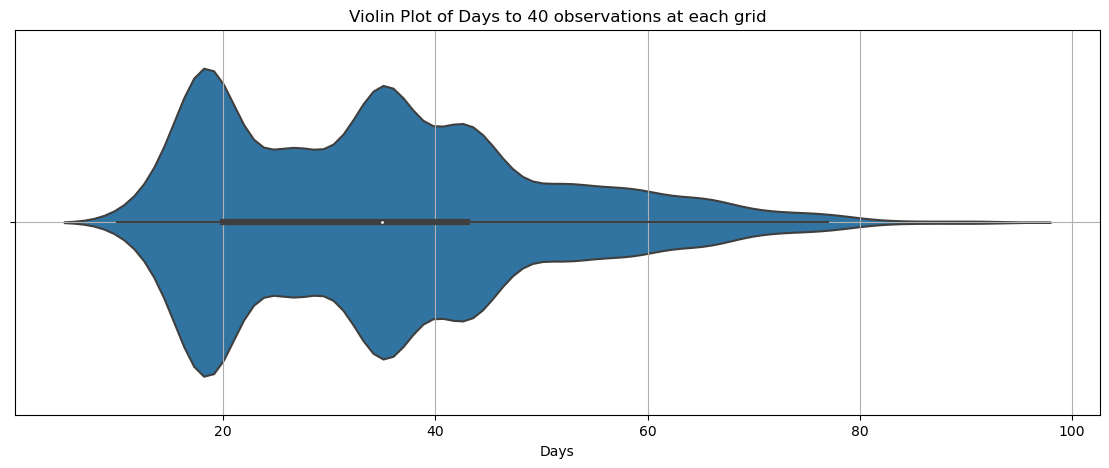

In [13]:
#violin plot 
plt.figure(figsize=(14,5))
sns.violinplot(x=obs_to_40_count['days_to_40_obs'])
plt.title('Violin Plot of Days to 40 observations at each grid')
plt.xlabel('Days')
plt.grid(True)
plt.show()

In [14]:
no2_df.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean', 'no2_std', 'no2_count',
       'no2_sem', 'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'datetime_utc', 'datetime_local', 'local_hour', 'state_name',
       'no2_scaled_by_hour'],
      dtype='object')

# Baseline Window Calculation 

In [15]:
baseline_window = 40 #minimum number of obs
max_time_window = 14 #max days of data

def compute_baseline(group):
    group=group.sort_values('datetime_local').reset_index(drop=True)
    rolling_mean=[]
    rolling_std=[]
    
    for i in range(len(group)):
        current_time= group.loc[i,'datetime_local']
        window_start= current_time - timedelta(days=max_time_window)

        #filtering data so that the window starts 14 days prior to current time and doesn't include current time 
        window_data= group[(group['datetime_local']< current_time) & (group['datetime_local']>= window_start)]
        valid_values= window_data['no2_scaled_by_hour'].dropna() #within valid window, 

        if len(valid_values)>=baseline_window: #if the # of valid vals are > than 50 obs, then can calculate the rolling mean!
            rolling_mean.append(valid_values.mean()) 
            rolling_std.append(valid_values.std())
        else:
            rolling_mean.append(np.nan)
            rolling_std.append(np.nan)

    group['rolling_mean'] =rolling_mean
    group['rolling_std'] = rolling_std
    return group

In [16]:
grouped = no2_df.sort_values(['grid_lat', 'grid_lon', 'datetime_local']).groupby(['grid_lat', 'grid_lon'])

results = []
for _, group in tqdm(grouped, desc='Computing baseline by grid cell'):
    result =compute_baseline(group)
    results.append(result)

no2_df =pd.concat(results).reset_index(drop=True)

Computing baseline by grid cell: 100%|██████████| 8969/8969 [20:19<00:00,  7.36it/s]


In [17]:
non_nan_rows_rolling_mean = no2_df['rolling_mean'].notna().sum()
print(f'the number of non NaN rolling mean rows is: {non_nan_rows_rolling_mean}')

NaN_rows = 2589516 - non_nan_rows_rolling_mean
print(f'the number of NaN rows is: {NaN_rows}')

percentage_non_nan = (non_nan_rows_rolling_mean / 2589516) * 100
print(f'the percentage of non NaN rolling mean rows is: {percentage_non_nan:.2f}%') 

the number of non NaN rolling mean rows is: 804788
the number of NaN rows is: 1784728
the percentage of non NaN rolling mean rows is: 31.08%


In [18]:
#detecting pulses
pulse_threshold =3
no2_pulse3SD = no2_df.copy()
no2_pulse3SD['pulse_threshold'] = no2_pulse3SD['rolling_mean'] + pulse_threshold * no2_pulse3SD['rolling_std']
no2_pulse3SD['pulse_event'] = no2_pulse3SD['no2_scaled_by_hour'] >= no2_pulse3SD['pulse_threshold']

count_pulse_3SD = no2_pulse3SD['pulse_event'].sum()
print(f'the amount of pulses detected with 3 SD is {count_pulse_3SD}')

the amount of pulses detected with 3 SD is 15219


In [19]:
#detecting pulses with 2+ consecutive hours as a pulse
pulse_threshold = 3

#sort and reset index to avoid alignment issues
df = no2_df.sort_values(["grid_lat","grid_lon","datetime_local"]).reset_index(drop=True).copy()

#apply pulse threshold and flag events that are above 3 SD of rolling mean 
df["pulse_threshold"] = df["rolling_mean"] + pulse_threshold * df["rolling_std"]
df["above_3sd"] =(df["no2_scaled_by_hour"] >= df["pulse_threshold"]).fillna(False)

g = df.groupby(["grid_lat","grid_lon"], sort=False)

#ask if the previous time point was above 3SD 
df["prev_above"] = g["above_3sd"].shift(1).fillna(False)

#create run IDs and Run lengths -- runs of Trues and Falses for if the previous value changed
df["run_id"]  = g["above_3sd"].transform(lambda s: s.ne(s.shift()).cumsum())
df["run_len"] = df.groupby(["grid_lat","grid_lon","run_id"])["above_3sd"].transform("size")

#label only the first row of runs with length >= 2 as a pulse start 
df["pulse_start"] = df["above_3sd"] & (~df["prev_above"]) & (df["run_len"] >= 2)


In [20]:
pulses_2hour=df.copy()
df_pulse_2hour_true = df[df['pulse_start']==True]
df_pulse_2hour_true.describe()

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,cv_no2,datetime_utc,datetime_local,local_hour,no2_scaled_by_hour,rolling_mean,rolling_std,pulse_threshold,run_id,run_len
count,2009,2009.000000,2009.000000,2.009000e+03,2.009000e+03,2009.000000,2.009000e+03,2009.000000,2009.000000,2009.000000,...,2009.000000,2009,2009,2009.000000,2.009000e+03,2.009000e+03,2.009000e+03,2.009000e+03,2009.000000,2009.000000
mean,2024-05-31 03:34:52.981582848,41.069313,-94.631782,3.392821e+15,1.000525e+15,23.368342,2.088245e+14,0.075660,0.005123,0.308377,...,0.296819,2024-05-31 03:34:52.981582848,2024-05-30 22:37:50.383275264,11.640119,2.825687e+15,1.129226e+15,3.836956e+14,2.280313e+15,4.168243,2.256844
min,2024-03-13 16:00:00,36.050000,-103.650000,1.452637e+15,1.848482e+14,13.000000,4.621204e+13,0.027748,0.000547,0.131187,...,0.065634,2024-03-13 16:00:00,2024-03-13 11:00:00,10.000000,1.259180e+15,5.021699e+14,1.609298e+14,1.040634e+15,2.000000,2.000000
25%,2024-04-25 17:00:00,39.650000,-98.050000,2.560076e+15,6.270572e+14,23.000000,1.291915e+14,0.066650,0.002845,0.280772,...,0.211285,2024-04-25 17:00:00,2024-04-25 12:00:00,10.000000,2.143216e+15,9.239797e+14,2.937933e+14,1.832706e+15,2.000000,2.000000
50%,2024-06-07 15:00:00,40.650000,-95.950000,3.048352e+15,8.526965e+14,25.000000,1.783072e+14,0.077272,0.004327,0.310379,...,0.277616,2024-06-07 15:00:00,2024-06-07 10:00:00,11.000000,2.559439e+15,1.084173e+15,3.521202e+14,2.143849e+15,4.000000,2.000000
75%,2024-06-24 15:00:00,42.450000,-90.150000,3.763359e+15,1.164945e+15,25.000000,2.480134e+14,0.085956,0.006512,0.338288,...,0.359594,2024-06-24 15:00:00,2024-06-24 10:00:00,12.000000,3.138090e+15,1.274006e+15,4.292232e+14,2.528328e+15,6.000000,2.000000
max,2024-07-26 15:00:00,48.550000,-81.750000,1.944495e+16,8.915927e+15,25.000000,1.783185e+15,0.098467,0.025680,0.431395,...,1.123332,2024-07-26 15:00:00,2024-07-26 10:00:00,18.000000,1.497755e+16,3.043778e+15,3.683805e+15,1.409519e+16,22.000000,8.000000
std,NaN,2.654577,4.477788,1.423164e+15,6.287247e+14,3.118304,1.310882e+14,0.012863,0.003212,0.041330,...,0.118970,NaN,NaN,2.200462,1.151676e+15,3.098471e+14,1.688253e+14,7.621059e+14,2.994279,0.694840


In [21]:
df['run_len'].describe()

count    2.589516e+06
mean     1.806409e+02
std      8.329097e+01
min      1.000000e+00
25%      1.130000e+02
50%      1.830000e+02
75%      2.430000e+02
max      4.590000e+02
Name: run_len, dtype: float64

In [22]:
pulses_2hour

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,state_name,no2_scaled_by_hour,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
0,2024-03-06 19:00:00,36.05,-91.15,9.690324e+14,2.402646e+14,15,6.203606e+13,0.085722,0.010582,0.287565,...,Arkansas,7.878814e+14,NaN,NaN,NaN,False,False,1,112,False
1,2024-03-06 20:00:00,36.05,-91.15,1.829055e+15,3.705986e+14,15,9.568816e+13,0.089425,0.008256,0.287554,...,Arkansas,1.408837e+15,NaN,NaN,NaN,False,False,1,112,False
2,2024-03-09 18:00:00,36.05,-91.15,1.141422e+15,7.019768e+14,25,1.403954e+14,0.059881,0.006153,0.214804,...,Arkansas,9.525667e+14,NaN,NaN,NaN,False,False,1,112,False
3,2024-03-09 19:00:00,36.05,-91.15,1.437166e+15,5.468697e+14,25,1.093739e+14,0.055169,0.005519,0.202981,...,Arkansas,1.168502e+15,NaN,NaN,NaN,False,False,1,112,False
4,2024-03-09 20:00:00,36.05,-91.15,9.113768e+14,3.456342e+14,25,6.912684e+13,0.056370,0.006833,0.200434,...,Arkansas,7.019917e+14,NaN,NaN,NaN,False,False,1,112,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2589511,2024-07-18 19:00:00,48.95,-96.85,1.123847e+15,6.826013e+14,21,1.489558e+14,0.060822,0.002307,0.252407,...,Minnesota,8.656479e+14,NaN,NaN,NaN,False,False,1,142,False
2589512,2024-07-28 16:00:00,48.95,-96.85,1.688912e+15,4.734627e+14,25,9.469254e+13,0.086393,0.001197,0.309960,...,Minnesota,1.444213e+15,NaN,NaN,NaN,False,False,1,142,False
2589513,2024-07-28 17:00:00,48.95,-96.85,1.974791e+15,3.152841e+14,25,6.305683e+13,0.080540,0.001058,0.292731,...,Minnesota,1.648049e+15,NaN,NaN,NaN,False,False,1,142,False
2589514,2024-07-30 16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25,1.077779e+14,0.092088,0.001035,0.323363,...,Minnesota,8.967192e+14,NaN,NaN,NaN,False,False,1,142,False


# Column Descriptions for NO₂ Pulse Detection Dataset

This dataset contains gridded hourly NO₂ observations along with derived variables used to detect pulse events.

---

## Time & Location

- **`date`**  
  Date of observation (YYYY-MM-DD)

- **`hour`**  
  Hour of observation (HH:MM:SS)

- **`datetime`**  
  Combined timestamp (`date + hour`) used for time-based analysis

- **`grid_lat`**  
  Latitude of the 0.1° grid cell

- **`grid_lon`**  
  Longitude of the 0.1° grid cell

---

##  NO₂ Observations

- **`no2_mean`**  
  Mean tropospheric NO₂ column within the grid cell (molec/cm²)

- **`no2_std`**  
  Standard deviation of NO₂ values within the grid cell

- **`no2_count`**  
  Number of valid satellite pixels contributing to the grid cell average

---

##  Cloud Filtering / Retrieval Diagnostics

- **`eff_cloud_fraction_mean`**  
  Mean effective cloud fraction (used to filter cloudy scenes)

- **`eff_cloud_fraction_std`**  
  Standard deviation of effective cloud fraction

- **`amf_cloud_fraction_mean`**  
  Mean cloud fraction used in air mass factor (AMF) calculations

- **`amf_cloud_fraction_std`**  
  Standard deviation of AMF cloud fraction

---

## Rolling Baseline (Background NO₂)

- **`rolling_mean`**  
  Mean NO₂ over the previous 14 days (excluding current time), used as background

- **`rolling_std`**  
  Standard deviation of NO₂ over the same rolling window

---

## Pulse Detection Variables

- **`pulse_threshold`**  
  Dynamic threshold for detecting pulses:  
  `rolling_mean + 3 × rolling_std`

- **`above_3sd`**  
  Boolean indicating whether NO₂ exceeds the pulse threshold

- **`prev_above`**  
  Boolean indicating whether the previous time step was also above threshold

---

## Run Tracking (Consecutive Events)

- **`run_id`**  
  Identifier for consecutive sequences of `above_3sd` values  
  (each continuous block of True/False values gets a unique ID)

- **`run_len`**  
  Length of the consecutive sequence (`run_id`) in hours

---

## Final Pulse Identification

- **`pulse_start`**  
  Boolean indicating the **start of a pulse event**, defined as:
  - NO₂ is above threshold (`above_3sd = True`)
  - Previous hour was not above threshold (`prev_above = False`)
  - Event lasts at least 2 consecutive hours (`run_len ≥ 2`)

---

## Summary

Pulse events represent **sustained, statistically significant increases in NO₂ relative to a local rolling baseline**, rather than isolated spikes.


In [23]:
output_file ='/global/scratch/users/toireasamarie/TEMPO/parquet_files/a10_lowCF_hour_scaled_GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours.parquet'
pulses_2hour.to_parquet(output_file, engine ='pyarrow')
print('saved to file')

saved to file
